<!-- Dr. Nam H. Le. drnamlabs.com, bunnyquant.com -->
# 04. Phase boundary or clock? The high-β threshold against run length

**Question.** At β = 6 the bank never collapsed within 4K generations, even with no outside data.
The original paper proved that with no outside data the bank must eventually contract.
So is the small α_c at high β a **real phase boundary**, or only the edge of how long we waited?

**Test.** One long run per (β, α, seed): K = 40, 3000 generations, census every 5 generations.
P_alive is read over three windows that end at 300, 1000 and 3000 generations.
A phase boundary stays put. A clock keeps moving right.

*Example.* Suppose at β = 4, α = 0.001, P_alive is 0.9 in the first window but 0.3 in the last.
Then the bank is dying slowly and α = 0.001 is not enough in the long run.

In [1]:
# Dr. Nam H. Le. drnamlabs.com, bunnyquant.com
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
FIG = Path('figures')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
z = np.load('data/sweep_runlength.npz')
betas, alphas, gens = z['betas'], z['alphas'], z['gens']
A, M, S = z['alive'], z['minority'], z['size']        # (beta, alpha, seed, time)
WINDOWS = [300, 1000, 3000]

def p_window(T):
    sel = (gens > T / 2) & (gens <= T)
    return A[..., sel].mean(-1)                         # (beta, alpha, seed)

def alpha_c(curve):
    la = np.log(np.where(alphas > 0, alphas, 1e-4))
    for i in range(len(alphas) - 1):
        if curve[i] < 0.5 <= curve[i + 1]:
            f = (0.5 - curve[i]) / (curve[i + 1] - curve[i])
            return float(np.exp(la[i] + f * (la[i + 1] - la[i])))
    return np.nan if curve[0] < 0.5 else 0.0

print('alpha_c by window (rows beta):', WINDOWS)
for bi, b in enumerate(betas):
    print(f'beta={b:g}', [round(alpha_c(p_window(T)[bi].mean(-1)), 4) for T in WINDOWS])

alpha_c by window (rows beta): [300, 1000, 3000]
beta=2 [0.3547, 0.3674, 0.369]
beta=3 [0.0262, 0.0268, 0.0244]
beta=4 [0.0017, 0.0008, 0.0005]
beta=6 [0.0, 0.0, 0.0]


## P_alive(α) in three windows

Solid = window ending at 3000 generations. If the curves for one β lie on top of each other, the boundary is real.

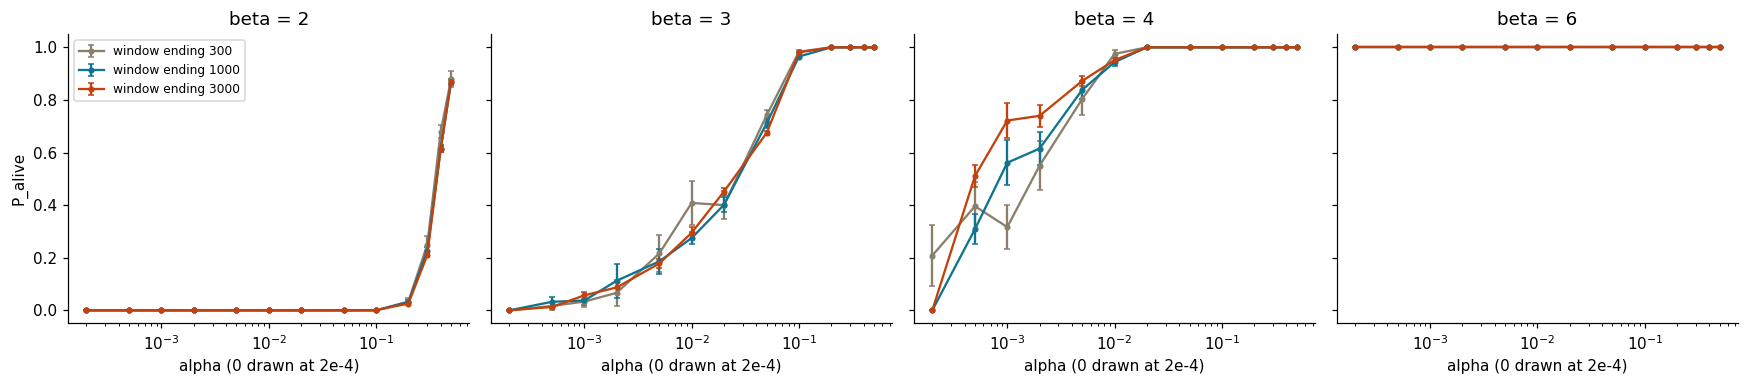

In [2]:
wc = {300: '#8a7f6a', 1000: '#0e7490', 3000: '#c2410c'}
fig, ax = plt.subplots(1, len(betas), figsize=(4 * len(betas), 3.6), sharey=True)
for bi, b in enumerate(betas):
    for T in WINDOWS:
        P = p_window(T)[bi]
        ax[bi].errorbar(np.where(alphas > 0, alphas, 2e-4), P.mean(-1), P.std(-1) / np.sqrt(P.shape[-1]),
                        fmt='o-', ms=3, capsize=2, color=wc[T], label=f'window ending {T}')
    ax[bi].set_xscale('log'); ax[bi].set(title=f'beta = {b:g}', xlabel='alpha (0 drawn at 2e-4)')
ax[0].set_ylabel('P_alive'); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'nb04_windows.png'); plt.show()

## No outside data (α = 0): what happens over 3000 generations?

Left: fraction of seeds still alive. Middle: minority-side fraction (0 = consensus). Right: mean |x| of the stored points (shrinkage).

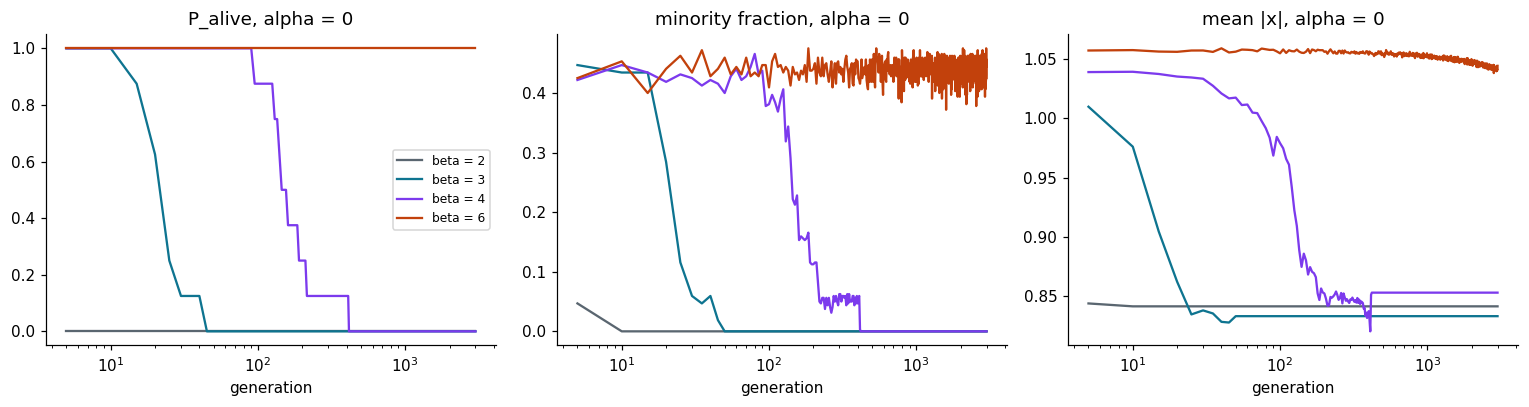

beta=2: collapse generation per seed [np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5)]
beta=3: collapse generation per seed [np.int64(25), np.int64(25), np.int64(15), np.int64(30), np.int64(20), np.int64(45), np.int64(20), np.int64(25)]
beta=4: collapse generation per seed [np.int64(415), np.int64(130), np.int64(95), np.int64(140), np.int64(190), np.int64(215), np.int64(160), np.int64(145)]
beta=6: collapse generation per seed [inf, inf, inf, inf, inf, inf, inf, inf]


In [3]:
bc = ['#5a6670', '#0e7490', '#7c3aed', '#c2410c']
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for bi, b in enumerate(betas):
    ax[0].plot(gens, A[bi, 0].mean(0), color=bc[bi], label=f'beta = {b:g}')
    ax[1].plot(gens, M[bi, 0].mean(0), color=bc[bi])
    ax[2].plot(gens, S[bi, 0].mean(0), color=bc[bi])
for a, t in zip(ax, ['P_alive, alpha = 0', 'minority fraction, alpha = 0', 'mean |x|, alpha = 0']):
    a.set(xscale='log', xlabel='generation', title=t)
ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'nb04_alpha0_time.png'); plt.show()

# first generation after which the bank stays dead to the end
for bi, b in enumerate(betas):
    tdeath = []
    for s in range(A.shape[2]):
        a = A[bi, 0, s]
        tdeath.append(gens[np.where(a)[0][-1] + 1] if a[-1] == 0 and a.any() else (gens[0] if not a.any() else np.inf))
    print(f'beta={b:g}: collapse generation per seed', tdeath)

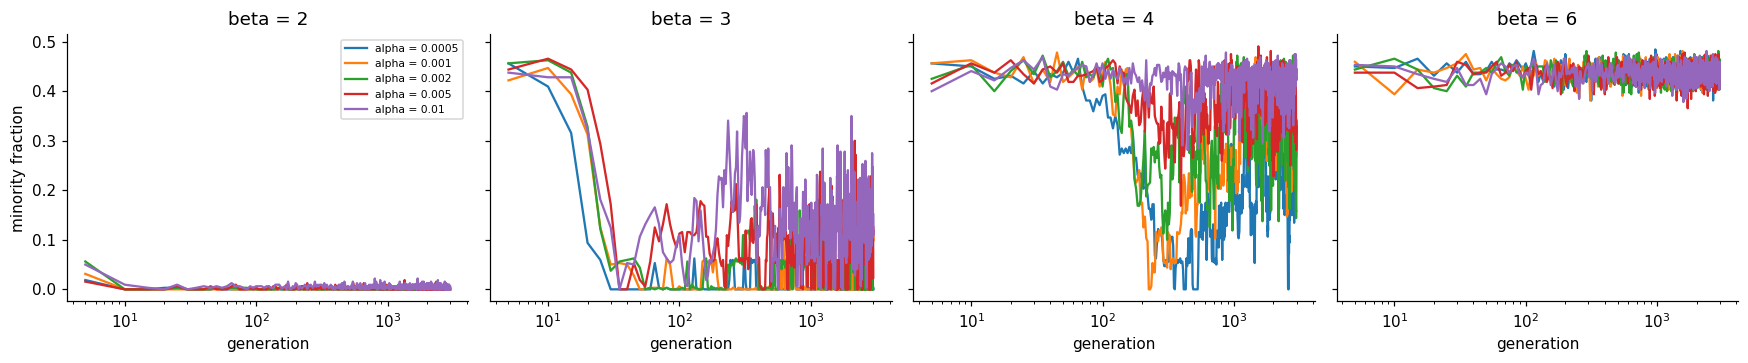

In [4]:
# slow drift check at the smallest positive alphas: minority fraction against time
fig, ax = plt.subplots(1, len(betas), figsize=(4 * len(betas), 3.4), sharey=True)
for bi, b in enumerate(betas):
    for ai in range(1, 6):
        ax[bi].plot(gens, M[bi, ai].mean(0), label=f'alpha = {alphas[ai]:g}')
    ax[bi].set(xscale='log', title=f'beta = {b:g}', xlabel='generation')
ax[0].set_ylabel('minority fraction'); ax[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / 'nb04_drift.png'); plt.show()

## Reading

**Both, at different places. With outside data (alpha > 0) the boundary is a true phase boundary. With none (alpha = 0) collapse always comes, on a clock that is exponential in beta.**

1. **alpha_c is stable in time at beta = 2 and 3.** By window (300 / 1000 / 3000 generations): beta = 2 gives 0.355 / 0.367 / 0.369, and beta = 3 gives 0.026 / 0.027 / 0.024. A factor of 10 in time does not move it, so this is a phase boundary.
2. **At beta = 4, alpha_c moves LEFT with time** (0.0017 -> 0.0008 -> 0.0005). Waiting longer makes the bank *more* alive at tiny alpha, because revival through rare fresh points is slow. The true alpha_c(4) is <= 0.0005, possibly 0+.
3. **At alpha = 0 every beta collapses; beta only sets when.** Median collapse is at generation 5 (beta = 2), ~25 (beta = 3) and ~150 (beta = 4). At beta = 6 nothing has collapsed by 3000 generations, but |x| has started to fall after ~1000 (right panel): shrinkage has begun.
4. **The clock looks Arrhenius-like.** Collapse time grows about x5-7 per unit beta, close to e^{2 beta m^2} (x7.4), which is the tail 1 - tanh(beta m^2) ~ 2 e^{-2 beta m^2} of the two-pattern map. Extrapolated to beta = 6: ~10^4 generations, beyond this run. The paper's "beta sets the clock" becomes a quantitative law, still to be fitted (step 6).
5. **Collapse = shrinkage first, then consensus.** At beta = 4, |x| falls from 1.04 to 0.85 while the minority side empties (middle and right panels move together).